# Lead Scoring Predictivo — X Education

**Objetivo general:** desarrollar un modelo predictivo que clasifique leads según su probabilidad de conversión,
y desplegarlo en un sistema funcional con **ranking de leads**, **sistema de priorización** y **dashboard comercial**.

**Dataset:** [Lead Scoring Case Study (Kaggle)](https://www.kaggle.com/code/kratikulhara/lead-scoring-case-study) — 9.240 leads, 37 columnas.

| Requerimiento | Dónde se cumple |
|---|---|
| Modelos de clasificación | Sección 5 (Regresión logística como línea base) |
| Feature engineering | Sección 4 (`features.py`) |
| Gradient Boosting y XGBoost | Sección 5 (con búsqueda de hiperparámetros para XGBoost) |
| Redes neuronales artificiales | Sección 5 (MLP, perceptrón multicapa) |
| Evaluación ROC-AUC | Sección 6 (CV + test, curvas ROC) |
| Ranking de leads / priorización | Sección 8 |
| Endpoint y dashboard | Sección 10 + carpetas `api/` y `dashboard/` del repositorio |

## 1. Configuración del entorno

In [1]:
import sys, os, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # Versiones fijadas para que el modelo exportado cargue igual en la API y el dashboard
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "scikit-learn==1.9.1", "xgboost==3.4.1"], check=True)

os.makedirs("data", exist_ok=True)
os.makedirs("models", exist_ok=True)
DATA_PATH = "data/Leads.csv"
if not os.path.exists(DATA_PATH):
    import urllib.request
    urllib.request.urlretrieve("https://raw.githubusercontent.com/shinde-chandrakant/Lead-Scoring-Case-Study/master/Leads.csv", DATA_PATH)
print("Dataset listo:", DATA_PATH)

Dataset listo: data/Leads.csv


In [2]:
import warnings, json, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, xgboost
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42
print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | xgboost 3.4.1 | pandas 3.0.5


## 2. Carga y exploración de datos (EDA)

In [3]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
print(f"Tasa de conversión global: {df['Converted'].mean():.1%}")
df.head()

(9240, 37)
Tasa de conversión global: 38.5%


,Prospect ID,Lead Number,Lead Origin,Lead Source,Do Not Email,Do Not Call,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,Last Activity,Country,Specialization,How did you hear about X Education,What is your current occupation,What matters most to you in choosing a course,Search,Magazine,Newspaper Article,X Education Forums,Newspaper,Digital Advertisement,Through Recommendations,Receive More Updates About Our Courses,Tags,Lead Quality,Update me on Supply Chain Content,Get updates on DM Content,Lead Profile,City,Asymmetrique Activity Index,Asymmetrique Profile Index,Asymmetrique Activity Score,Asymmetrique Profile Score,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,660737,API,Olark Chat,No,No,0,0.0,0,0.0,Page Visited on Website,NaN,Select,Select,Unemployed,Better Career Prospects,No,No,No,No,No,No,No,No,Interested in other courses,Low in Relevance,No,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Modified
1,2a272436-5132-4136-86fa-dcc88c88f482,660728,API,Organic Search,No,No,0,5.0,674,2.5,Email Opened,India,Select,Select,Unemployed,Better Career Prospects,No,No,No,No,No,No,No,No,Ringing,NaN,No,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Email Opened
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,660727,Landing Page Submission,Direct Traffic,No,No,1,2.0,1532,2.0,Email Opened,India,Business Administration,Select,Student,Better Career Prospects,No,No,No,No,No,No,No,No,Will revert after reading the email,Might be,No,No,Potential Lead,Mumbai,02.Medium,01.High,14.0,20.0,No,Yes,Email Opened
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,660719,Landing Page Submission,Direct Traffic,No,No,0,1.0,305,1.0,Unreachable,India,Media and Advertising,Word Of Mouth,Unemployed,Better Career Prospects,No,No,No,No,No,No,No,No,Ringing,Not Sure,No,No,Select,Mumbai,02.Medium,01.High,13.0,17.0,No,No,Modified
4,3256f628-e534-4826-9d63-4a8b88782852,660681,Landing Page Submission,Google,No,No,1,2.0,1428,1.0,Converted to Lead,India,Select,Other,Unemployed,Better Career Prospects,No,No,No,No,No,No,No,No,Will revert after reading the email,Might be,No,No,Select,Mumbai,02.Medium,01.High,15.0,18.0,No,No,Modified


En el dataset, el valor **`Select`** significa que el usuario no eligió nada en el formulario,
así que en realidad es un **valor faltante**. Lo reemplazamos antes de medir nulos.

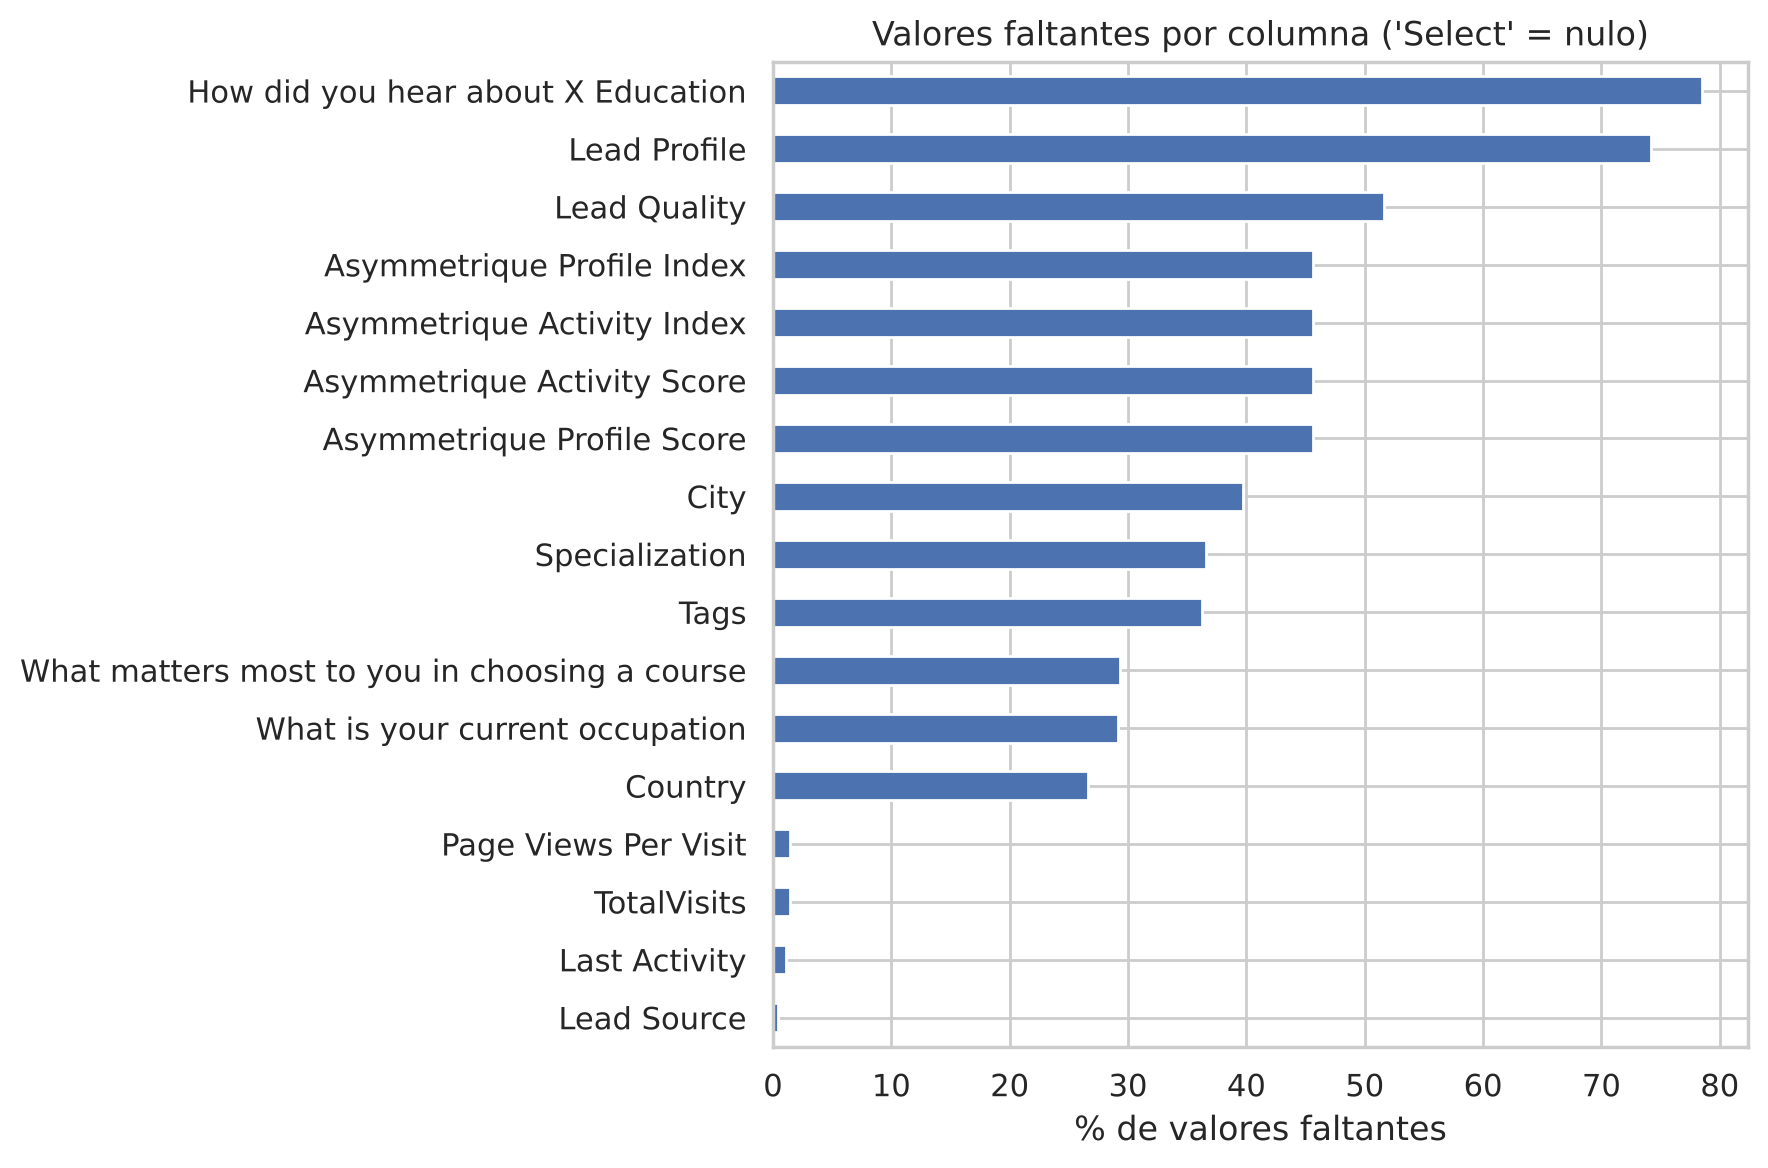

In [4]:
raw = df.replace("Select", np.nan)
missing = (raw.isna().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]
fig, ax = plt.subplots(figsize=(9, 6))
missing.plot.barh(ax=ax, color="#4C72B0")
ax.invert_yaxis(); ax.set_xlabel("% de valores faltantes"); ax.set_title("Valores faltantes por columna ('Select' = nulo)")
plt.tight_layout(); plt.show()

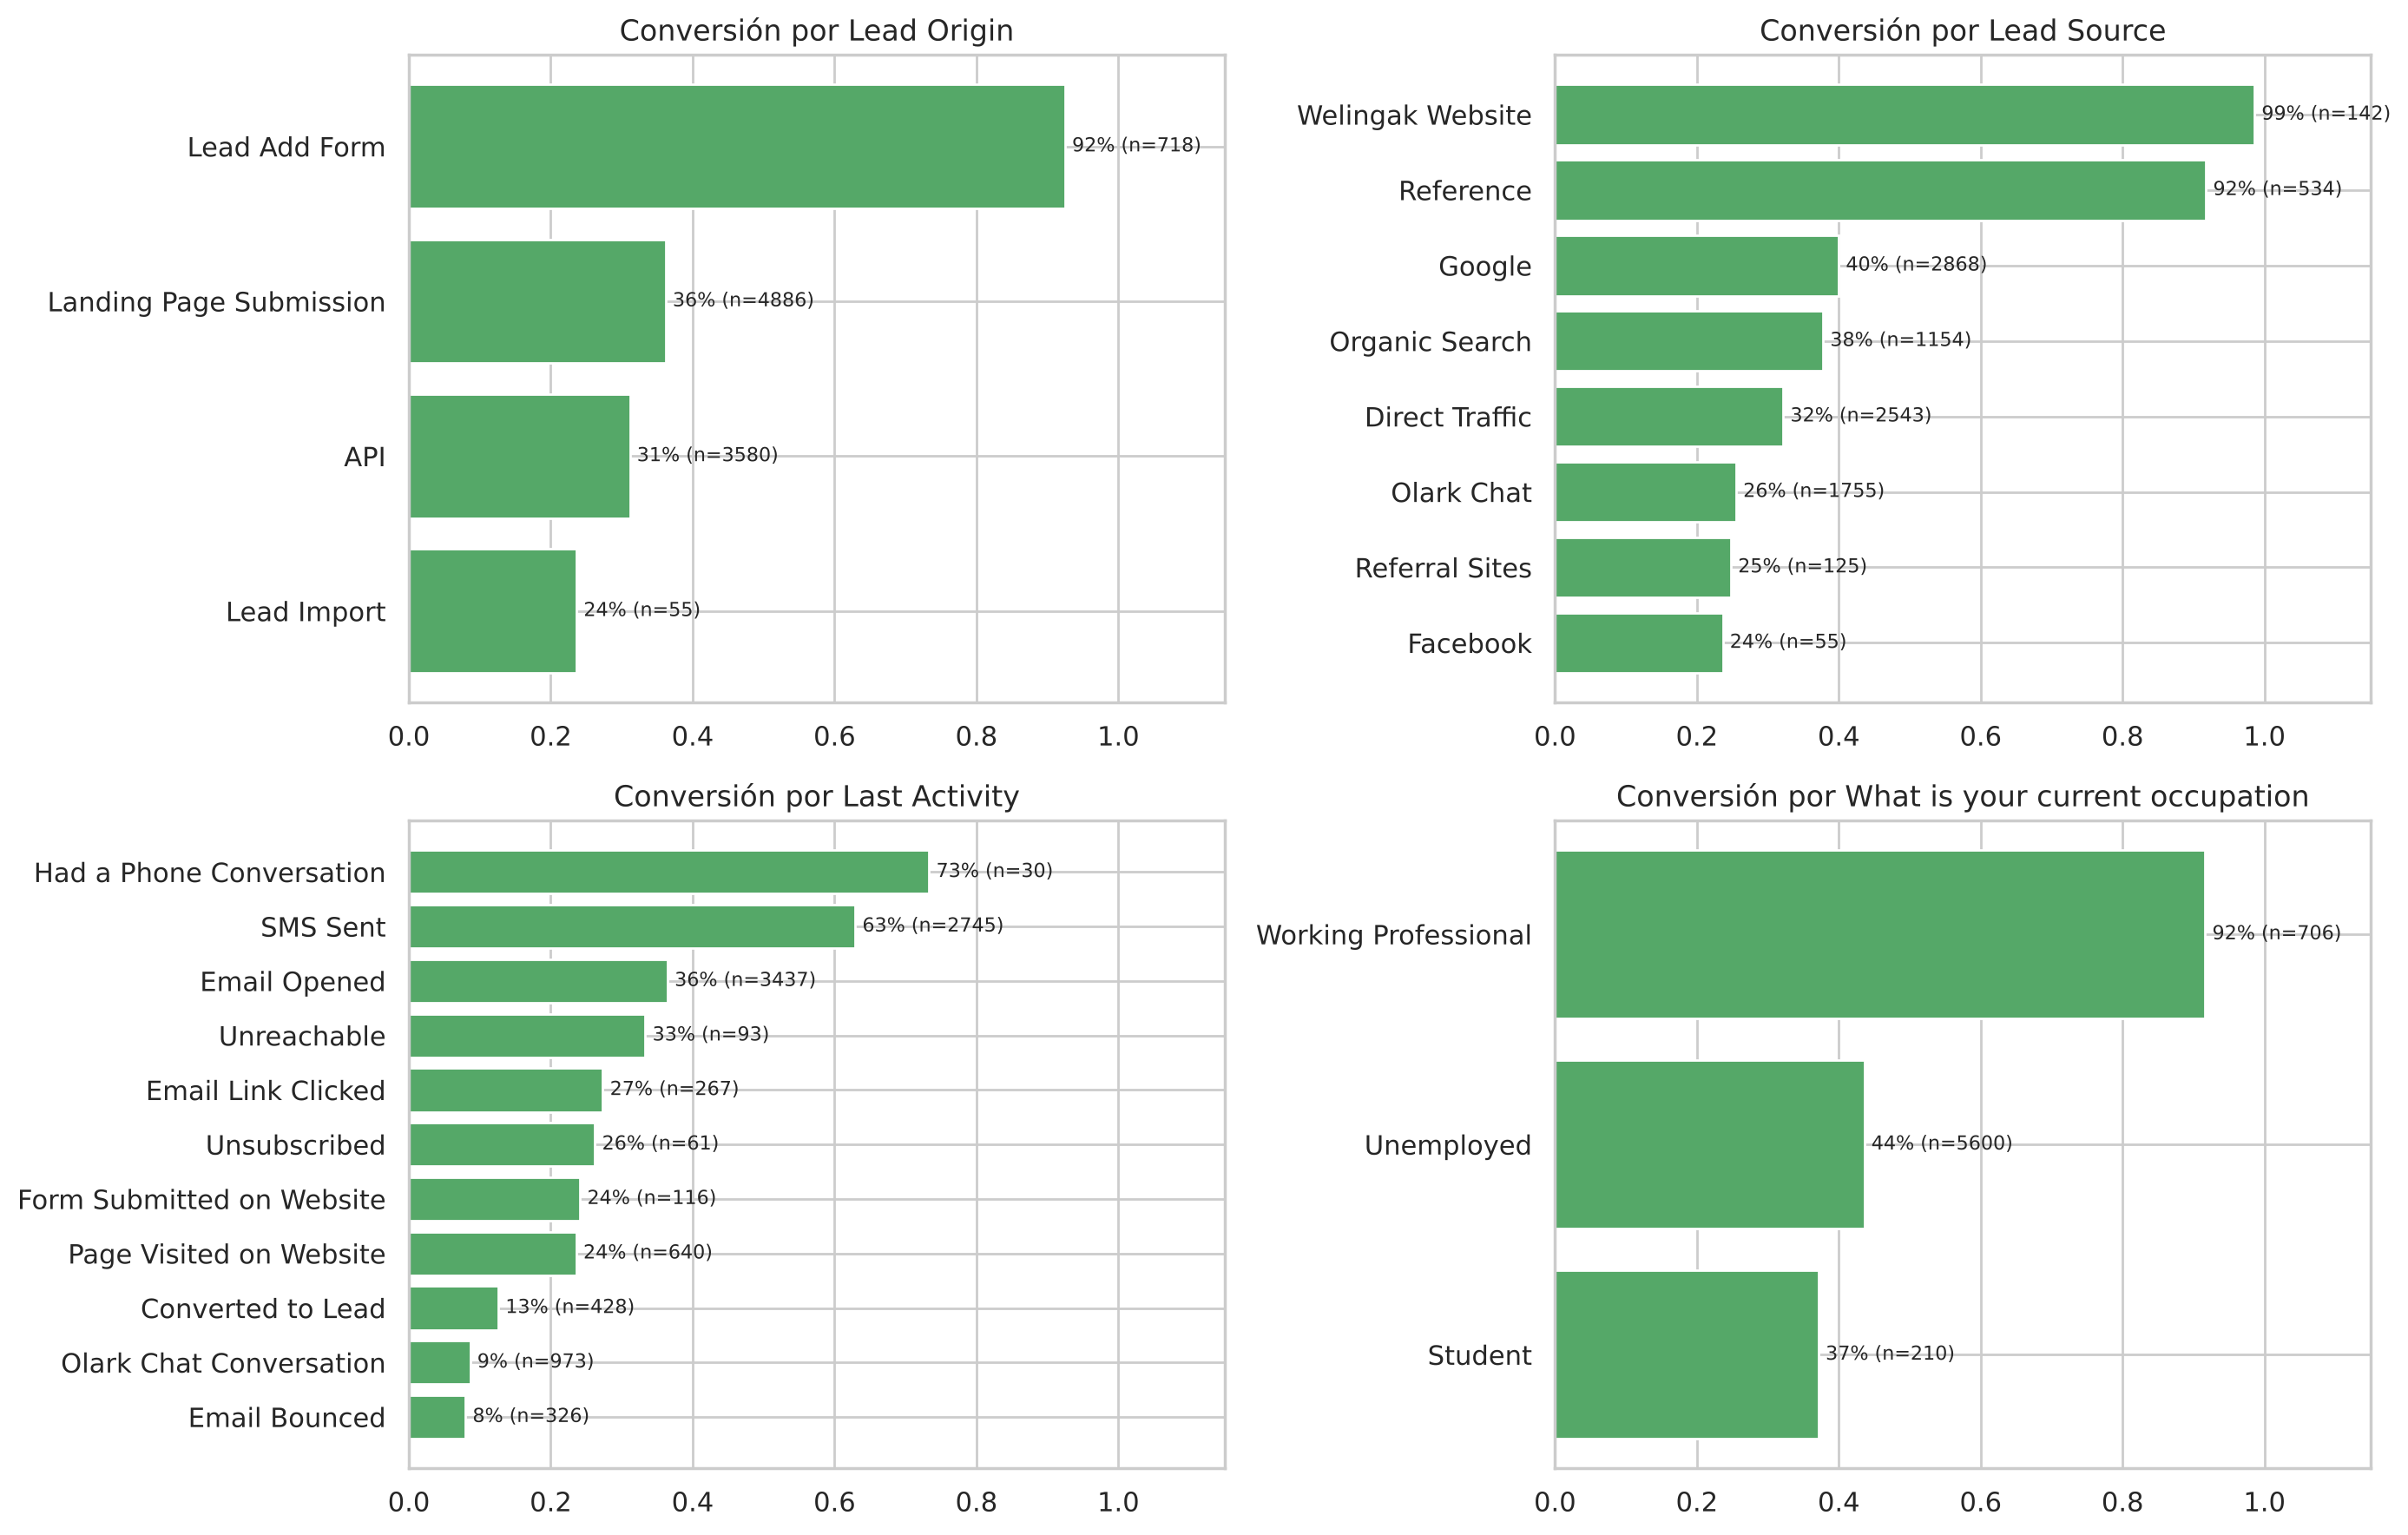

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), ["Lead Origin", "Lead Source", "Last Activity", "What is your current occupation"]):
    g = raw.groupby(col)["Converted"].agg(["mean", "size"]).query("size >= 30").sort_values("mean")
    ax.barh(g.index.astype(str), g["mean"], color="#55A868")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(m + 0.01, i, f"{m:.0%} (n={n})", va="center", fontsize=8)
    ax.set_xlim(0, 1.15); ax.set_title(f"Conversión por {col}")
plt.tight_layout(); plt.show()

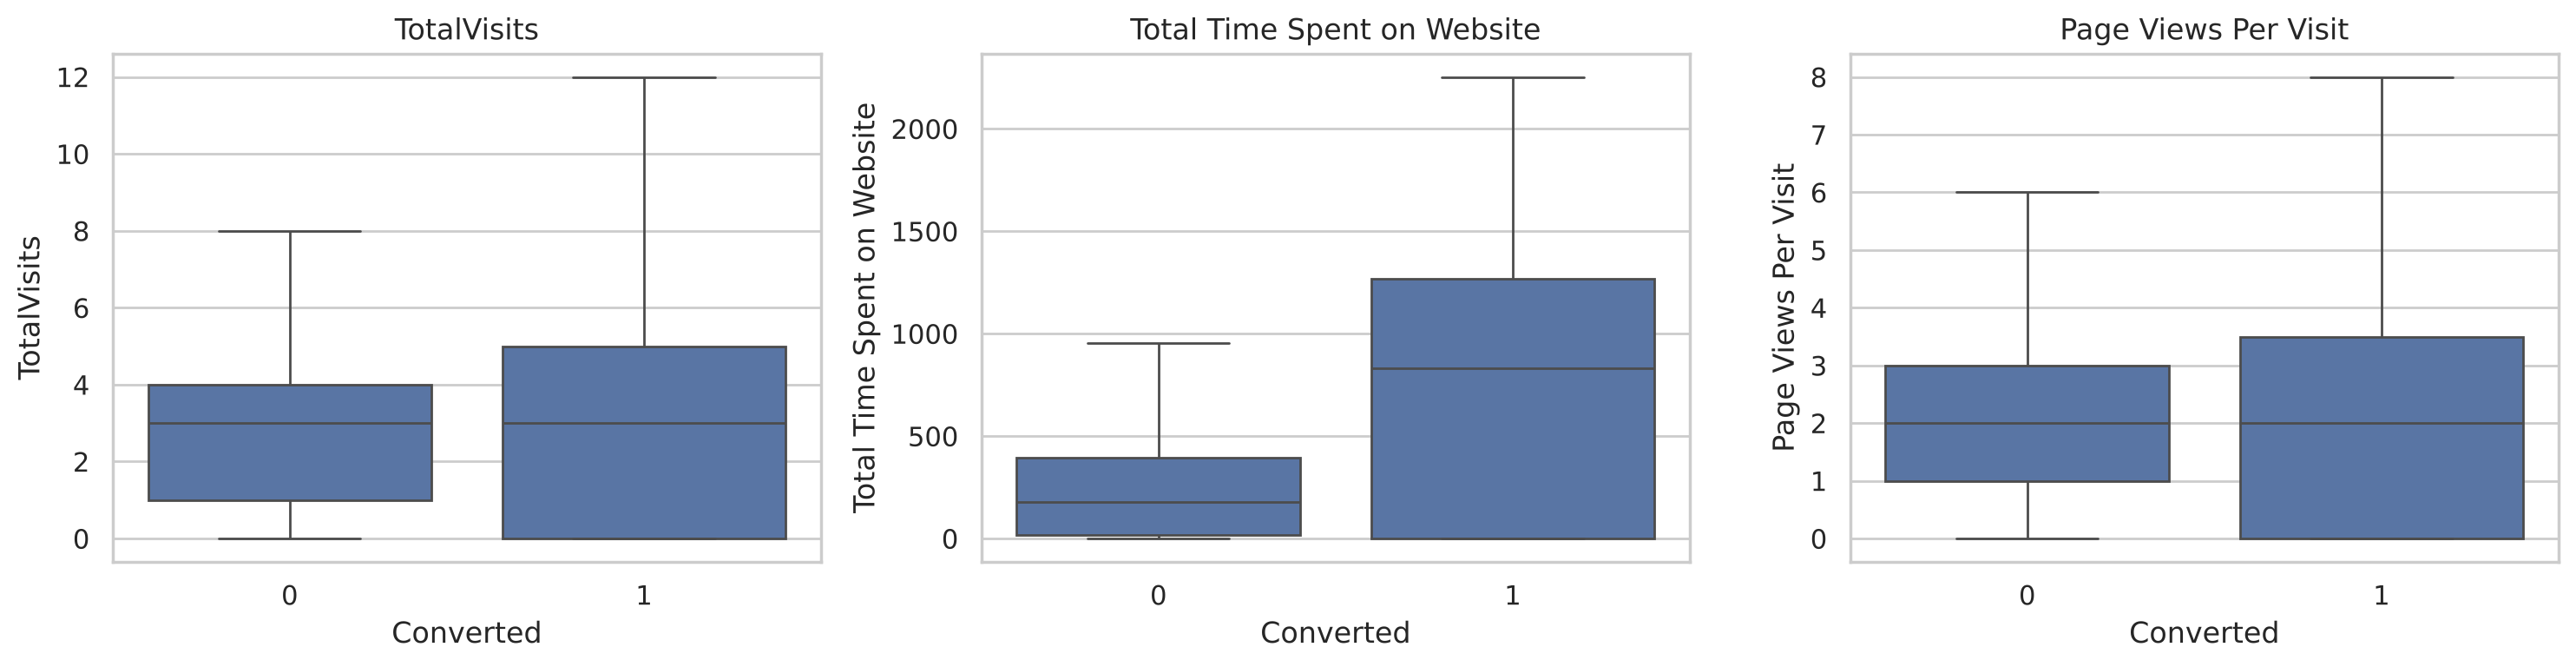

,count,mean,std,min,50%,95%,99%,max
TotalVisits,9103.0,3.445238,4.854853,0.0,3.0,10.0,17.00,251.0
Total Time Spent on Website,9240.0,487.698268,548.021466,0.0,248.0,1562.0,1840.61,2272.0
Page Views Per Visit,9103.0,2.362820,2.161418,0.0,2.0,6.0,9.00,55.0


In [6]:
num_cols = ["TotalVisits", "Total Time Spent on Website", "Page Views Per Visit"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=raw, x="Converted", y=c, ax=ax, showfliers=False)
    ax.set_title(c)
plt.tight_layout(); plt.show()
raw[num_cols].describe(percentiles=[.5, .95, .99]).T

**Hallazgos del EDA**
- La conversión global es ~38.5%, así que las clases están moderadamente desbalanceadas.
- **Tiempo en el sitio** es la variable numérica más discriminante: quienes convierten pasan mucho más tiempo.
- `Lead Add Form` (92%) y los **Working Professionals** (92%) convierten muchísimo más que el promedio.
- `TotalVisits` y `Page Views Per Visit` tienen outliers extremos (máx. 251 y 55), así que se recortan al percentil 99.

## 3. Detección de fuga de información (data leakage)

In [7]:
leak = raw.groupby("Tags")["Converted"].agg(["mean", "size"]).sort_values("size", ascending=False).head(10)
leak.style.format({"mean": "{:.0%}"}).background_gradient(subset="mean", cmap="RdYlGn")

,mean,size
Tags,,
Will revert after reading the email,97%,2072
Ringing,3%,1203
Interested in other courses,3%,513
Already a student,1%,465
Closed by Horizzon,99%,358
switched off,2%,240
Busy,56%,186
Lost to EINS,98%,175
Not doing further education,1%,145


`Tags` contiene valores como *"Closed by Horizzon"* (99% de conversión) o *"Lost to EINS"*, que el equipo comercial
registra **después** de trabajar el lead. Lo mismo pasa con `Lead Quality`, `Lead Profile` y los índices `Asymmetrique`.

Incluirlas daría un ROC-AUC artificialmente alto (~0.98), pero el modelo **no serviría** para priorizar un lead nuevo,
porque al llegar ese lead todavía no tiene esos datos. **Por eso se excluyen.** El modelo solo usa información
disponible en el momento en que entra el lead.

## 4. Feature engineering

Todas las transformaciones viven en un módulo (`features.py`) que comparten el notebook, la API y el dashboard,
así el modelo desplegado recibe exactamente el mismo preprocesamiento que en el entrenamiento.

| Feature | Descripción |
|---|---|
| `log_time_on_site` | log(1 + tiempo en el sitio), para suavizar la asimetría |
| `time_per_visit` | tiempo / (visitas + 1): profundidad de cada visita |
| `total_page_views` | visitas × páginas por visita |
| `engagement_index` | promedio normalizado de tiempo, visitas y páginas |
| `high_intent_activity` | la última actividad es SMS, llamada, clic en email o formulario enviado |
| `is_working_professional` | ocupación = Working Professional |
| `*_missing` | indicadores de faltante (no responder también es información) |
| `is_india`, `do_not_email`, `free_copy` | binarias |
| Categóricas | One-hot con agrupación automática de categorías raras (< 30 casos) |

In [8]:
%%writefile features.py
"""
features.py — Limpieza, feature engineering y reglas de priorización.

Lo usan el notebook (entrenamiento), la API (FastAPI) y el dashboard (Streamlit),
para que el modelo reciba exactamente las mismas transformaciones en todos lados.
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

TARGET = "Converted"
ID_COLS = ["Prospect ID", "Lead Number"]

# Columnas que se llenan DESPUÉS del contacto comercial (fuga de información / data leakage).
# Ej.: Tags = "Closed by Horizzon" convierte 99%; "Lead Quality" la asigna el vendedor.
# Un modelo de lead scoring debe puntuar al lead cuando llega, así que se excluyen.
LEAKY_COLS = [
    "Tags",
    "Lead Quality",
    "Lead Profile",
    "Asymmetrique Activity Index",
    "Asymmetrique Profile Index",
    "Asymmetrique Activity Score",
    "Asymmetrique Profile Score",
    "Last Notable Activity",  # redundante con Last Activity y se actualiza en el tiempo
]

# Columnas casi constantes (>99% un solo valor) o con demasiados faltantes.
LOW_INFO_COLS = [
    "Do Not Call", "Search", "Magazine", "Newspaper Article", "X Education Forums",
    "Newspaper", "Digital Advertisement", "Through Recommendations",
    "Receive More Updates About Our Courses", "Update me on Supply Chain Content",
    "Get updates on DM Content", "I agree to pay the amount through cheque",
    "What matters most to you in choosing a course",  # 99.9% "Better Career Prospects"
    "How did you hear about X Education",  # 78% faltante
]

# Campos crudos que el modelo necesita como entrada (lo que llega de un formulario / CRM).
INPUT_COLS = [
    "Lead Origin",
    "Lead Source",
    "Do Not Email",
    "TotalVisits",
    "Total Time Spent on Website",
    "Page Views Per Visit",
    "Last Activity",
    "Country",
    "Specialization",
    "What is your current occupation",
    "City",
    "A free copy of Mastering The Interview",
]

NUMERIC_FEATURES = [
    "TotalVisits",
    "Total Time Spent on Website",
    "Page Views Per Visit",
    "log_time_on_site",
    "time_per_visit",
    "total_page_views",
    "engagement_index",
    "do_not_email",
    "free_copy",
    "is_india",
    "occupation_missing",
    "specialization_missing",
    "city_missing",
    "is_working_professional",
    "high_intent_activity",
    "no_activity_visit",
]

CATEGORICAL_FEATURES = [
    "Lead Origin",
    "Lead Source",
    "Last Activity",
    "Specialization",
    "What is your current occupation",
    "City",
]

# Topes para outliers (≈ percentil 99 del dataset de entrenamiento).
CAPS = {"TotalVisits": 17, "Page Views Per Visit": 9, "Total Time Spent on Website": 2272}

# Actividades que indican intención alta de compra.
HIGH_INTENT = {"SMS Sent", "Had a Phone Conversation", "Email Link Clicked", "Form Submitted on Website"}

SOURCE_FIXES = {"google": "Google", "Facebook": "Social Media", "bing": "Search Engines",
                "Click2call": "Other", "Press_Release": "Other", "Social Media": "Social Media",
                "Live Chat": "Olark Chat", "youtubechannel": "Social Media",
                "testone": "Other", "Pay per Click Ads": "Other", "welearnblog_Home": "Other",
                "WeLearn": "Other", "blog": "Other", "NC_EDM": "Other"}


def clean_raw(df: pd.DataFrame) -> pd.DataFrame:
    """Limpieza básica: 'Select' → nulo, nombres de fuentes unificados, tipos numéricos."""
    df = df.copy()
    df = df.replace("Select", np.nan)
    for c in INPUT_COLS:
        if c not in df.columns:
            df[c] = np.nan
    if "Lead Source" in df:
        df["Lead Source"] = df["Lead Source"].replace(SOURCE_FIXES)
    for c in ["TotalVisits", "Total Time Spent on Website", "Page Views Per Visit"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    return df


class LeadFeatureEngineer(BaseEstimator, TransformerMixin):
    """Transforma registros crudos de leads en las features del modelo."""

    def fit(self, X, y=None):
        X = clean_raw(pd.DataFrame(X))
        self.medians_ = {
            c: float(X[c].median())
            for c in ["TotalVisits", "Total Time Spent on Website", "Page Views Per Visit"]
        }
        return self

    def transform(self, X):
        X = clean_raw(pd.DataFrame(X))
        out = pd.DataFrame(index=X.index)

        # Numéricas con imputación por mediana y tope de outliers
        for c, cap in CAPS.items():
            out[c] = X[c].fillna(self.medians_[c]).clip(lower=0, upper=cap)

        visits = out["TotalVisits"]
        time = out["Total Time Spent on Website"]
        ppv = out["Page Views Per Visit"]

        # Features derivadas de engagement
        out["log_time_on_site"] = np.log1p(time)
        out["time_per_visit"] = time / (visits + 1)
        out["total_page_views"] = visits * ppv
        out["engagement_index"] = (
            time / CAPS["Total Time Spent on Website"]
            + visits / CAPS["TotalVisits"]
            + ppv / CAPS["Page Views Per Visit"]
        ) / 3
        out["no_activity_visit"] = (visits == 0).astype(int)

        # Binarias
        yes = lambda s: s.astype(str).str.strip().str.lower().eq("yes").astype(int)
        out["do_not_email"] = yes(X["Do Not Email"])
        out["free_copy"] = yes(X["A free copy of Mastering The Interview"])
        out["is_india"] = X["Country"].fillna("India").eq("India").astype(int)

        # Indicadores de faltantes (el faltante también es información)
        out["occupation_missing"] = X["What is your current occupation"].isna().astype(int)
        out["specialization_missing"] = X["Specialization"].isna().astype(int)
        out["city_missing"] = X["City"].isna().astype(int)

        out["is_working_professional"] = X["What is your current occupation"].eq("Working Professional").astype(int)
        out["high_intent_activity"] = X["Last Activity"].isin(HIGH_INTENT).astype(int)

        # Categóricas (faltante → "Desconocido")
        for c in CATEGORICAL_FEATURES:
            out[c] = X[c].astype("object").where(X[c].notna(), "Desconocido").astype(str)

        return out[NUMERIC_FEATURES + CATEGORICAL_FEATURES]


# ---------------------------------------------------------------- Priorización
TIERS = [  # (score mínimo, nivel, acción sugerida)
    (70, "Caliente", "Llamar hoy: asignar a un asesor senior"),
    (40, "Tibio", "Contactar esta semana: llamada + email personalizado"),
    (0, "Frío", "Nurturing automático: secuencia de emails / SMS"),
]


def priority_from_score(score: float) -> tuple[str, str]:
    for threshold, tier, action in TIERS:
        if score >= threshold:
            return tier, action
    return TIERS[-1][1], TIERS[-1][2]


def score_leads(model, df: pd.DataFrame) -> pd.DataFrame:
    """Devuelve el DataFrame con score (0-100), prioridad, acción y posición en el ranking."""
    proba = np.asarray(model.predict_proba(df)[:, 1], dtype=float)
    out = df.copy()
    out["probabilidad"] = proba.round(4)
    out["score"] = (proba * 100).round(1)
    pr = out["score"].apply(priority_from_score)
    out["prioridad"] = [p[0] for p in pr]
    out["accion_sugerida"] = [p[1] for p in pr]
    out = out.sort_values("score", ascending=False)
    out["ranking"] = np.arange(1, len(out) + 1)
    return out


Overwriting features.py


In [9]:
import importlib, features
importlib.reload(features)
from features import (LeadFeatureEngineer, INPUT_COLS, NUMERIC_FEATURES, CATEGORICAL_FEATURES,
                      TARGET, TIERS, score_leads)

X = df[INPUT_COLS].copy()
y = df[TARGET].copy()
fe_demo = LeadFeatureEngineer().fit(X)
fe_demo.transform(X).head()

,TotalVisits,Total Time Spent on Website,Page Views Per Visit,log_time_on_site,time_per_visit,total_page_views,engagement_index,do_not_email,free_copy,is_india,occupation_missing,specialization_missing,city_missing,is_working_professional,high_intent_activity,no_activity_visit,Lead Origin,Lead Source,Last Activity,Specialization,What is your current occupation,City
0,0.0,0,0.0,0.000000,0.000000,0.0,0.000000,0,0,1,0,1,1,0,0,1,API,Olark Chat,Page Visited on Website,Desconocido,Unemployed,Desconocido
1,5.0,674,2.5,6.514713,112.333333,12.5,0.289517,0,0,1,0,1,1,0,0,0,API,Organic Search,Email Opened,Desconocido,Unemployed,Desconocido
2,2.0,1532,2.0,7.334982,510.666667,4.0,0.338055,0,1,1,0,0,0,0,0,0,Landing Page Submission,Direct Traffic,Email Opened,Business Administration,Student,Mumbai
3,1.0,305,1.0,5.723585,152.500000,1.0,0.101393,0,0,1,0,0,0,0,0,0,Landing Page Submission,Direct Traffic,Unreachable,Media and Advertising,Unemployed,Mumbai
4,2.0,1428,1.0,7.264730,476.000000,2.0,0.285760,0,0,1,0,1,0,0,0,0,Landing Page Submission,Google,Converted to Lead,Desconocido,Unemployed,Mumbai


## 5. Modelos de clasificación

In [10]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

def make_pipeline(model):
    preprocess = ColumnTransformer([
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False),
         CATEGORICAL_FEATURES),
    ])
    return Pipeline([("features", LeadFeatureEngineer()), ("preprocess", preprocess), ("model", model)])

Train: (7392, 12) | Test: (1848, 12)


Se comparan cuatro familias de modelos:
1. **Regresión logística**: línea base interpretable.
2. **Gradient Boosting** (scikit-learn).
3. **XGBoost**, con búsqueda aleatoria de hiperparámetros (RandomizedSearchCV, 5 folds, optimizando ROC-AUC).
4. **Red neuronal artificial**: perceptrón multicapa (64 → 32 neuronas, ReLU, Adam, early stopping).

In [11]:
xgb_search = RandomizedSearchCV(
    make_pipeline(XGBClassifier(eval_metric="auc", random_state=RANDOM_STATE, n_jobs=-1)),
    param_distributions={
        "model__n_estimators": [200, 300, 400, 600],
        "model__learning_rate": [0.02, 0.03, 0.05, 0.08, 0.1],
        "model__max_depth": [3, 4, 5, 6],
        "model__min_child_weight": [1, 3, 5],
        "model__subsample": [0.7, 0.8, 0.9, 1.0],
        "model__colsample_bytree": [0.6, 0.8, 1.0],
        "model__reg_lambda": [0.5, 1, 2, 5],
    },
    n_iter=20, scoring="roc_auc", cv=cv, random_state=RANDOM_STATE, n_jobs=-1,
)
t0 = time.time()
xgb_search.fit(X_train, y_train)
print(f"Mejor ROC-AUC CV XGBoost: {xgb_search.best_score_:.4f} ({time.time()-t0:.0f}s)")
print({k.replace('model__', ''): v for k, v in xgb_search.best_params_.items()})

Mejor ROC-AUC CV XGBoost: 0.9072 (24s)
{'subsample': 0.9, 'reg_lambda': 0.5, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.02, 'colsample_bytree': 0.6}


In [12]:
models = {
    "Regresión Logística": make_pipeline(LogisticRegression(max_iter=2000, C=1.0)),
    "Gradient Boosting": make_pipeline(GradientBoostingClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=RANDOM_STATE)),
    "XGBoost (tuned)": xgb_search.best_estimator_,
    "Red Neuronal (MLP)": make_pipeline(MLPClassifier(
        hidden_layer_sizes=(64, 32), activation="relu", alpha=1e-3, learning_rate_init=1e-3,
        early_stopping=True, validation_fraction=0.15, max_iter=500, random_state=RANDOM_STATE)),
}

results, test_probas = [], {}
for name, pipe in models.items():
    t0 = time.time()
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    test_probas[name] = p
    results.append({
        "Modelo": name,
        "ROC-AUC CV (media)": cv_auc.mean(),
        "ROC-AUC CV (desv.)": cv_auc.std(),
        "ROC-AUC Test": roc_auc_score(y_test, p),
        "PR-AUC Test": average_precision_score(y_test, p),
        "F1 Test (umbral 0.5)": f1_score(y_test, (p >= 0.5).astype(int)),
        "Tiempo (s)": round(time.time() - t0, 1),
    })
results_df = pd.DataFrame(results).sort_values("ROC-AUC CV (media)", ascending=False).reset_index(drop=True)
results_df.style.format(precision=4).highlight_max(subset=["ROC-AUC CV (media)", "ROC-AUC Test", "PR-AUC Test"], color="#c7e9c0")

,Modelo,ROC-AUC CV (media),ROC-AUC CV (desv.),ROC-AUC Test,PR-AUC Test,F1 Test (umbral 0.5),Tiempo (s)
0,XGBoost (tuned),0.9072,0.0027,0.8902,0.8346,0.7730,1.6000
1,Gradient Boosting,0.9053,0.0027,0.8904,0.8325,0.7668,11.8000
2,Red Neuronal (MLP),0.9034,0.0032,0.8777,0.8131,0.7417,2.0000
3,Regresión Logística,0.8997,0.0039,0.8779,0.8148,0.7352,0.6000


## 6. Evaluación: curvas ROC

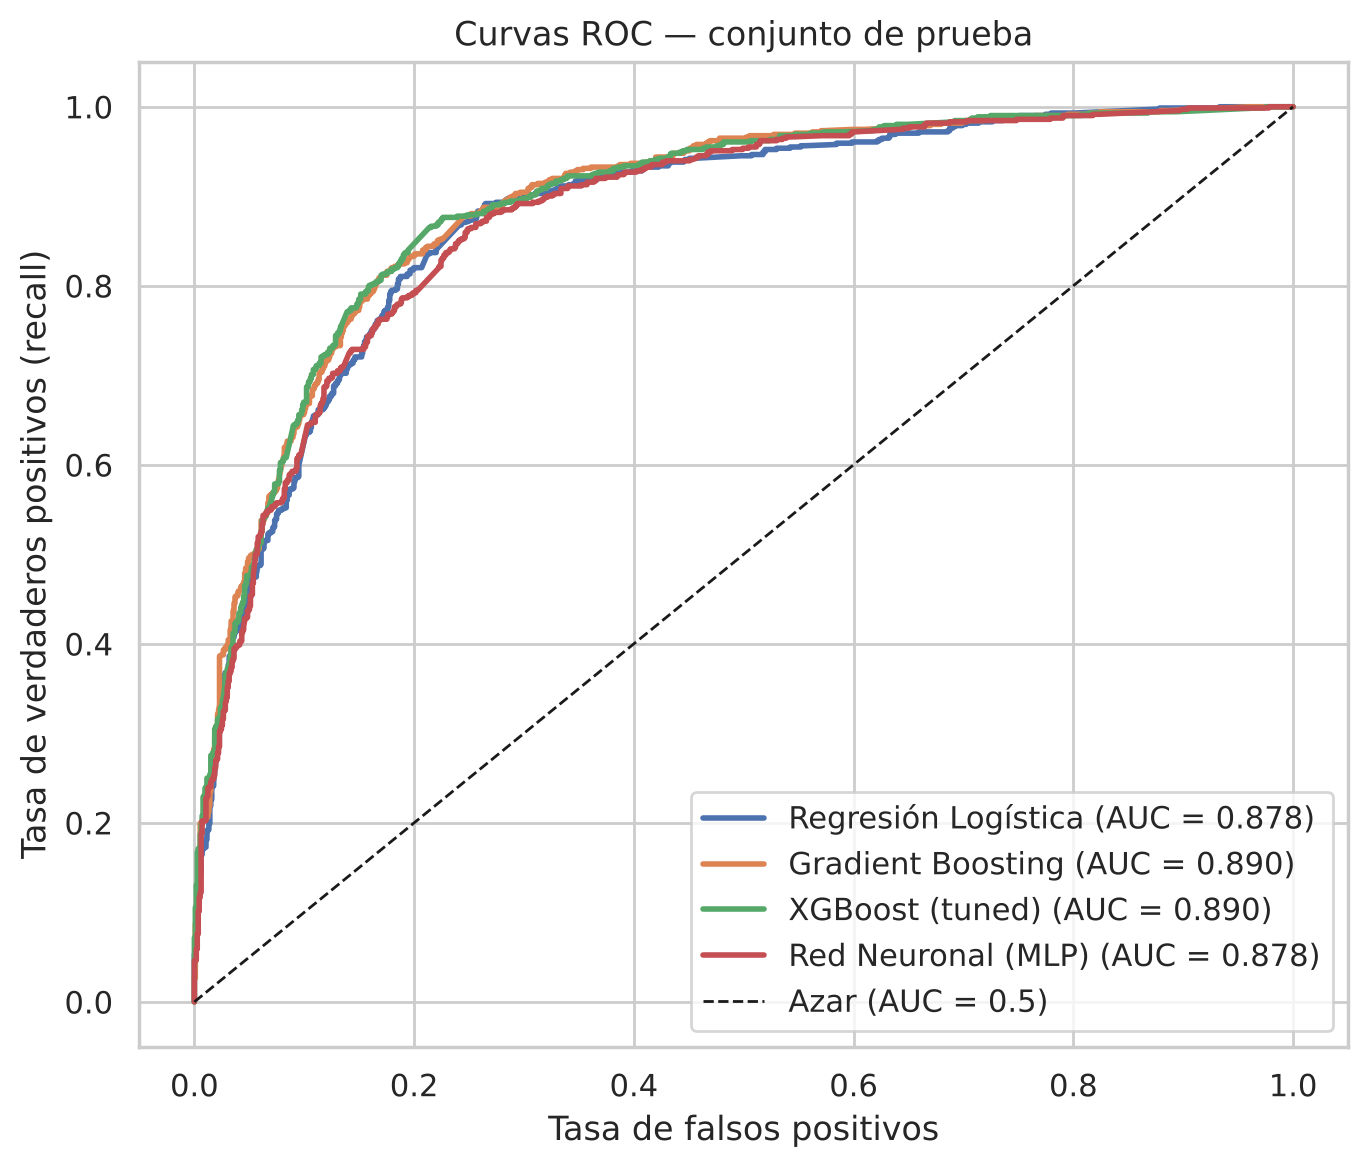

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, p in test_probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC = 0.5)")
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos (recall)")
ax.set_title("Curvas ROC — conjunto de prueba"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Modelo seleccionado: XGBoost (tuned)  |  umbral óptimo = 0.334

              precision    recall  f1-score   support

No convierte       0.90      0.79      0.84      1136
   Convierte       0.72      0.87      0.78       712

    accuracy                           0.82      1848
   macro avg       0.81      0.83      0.81      1848
weighted avg       0.83      0.82      0.82      1848



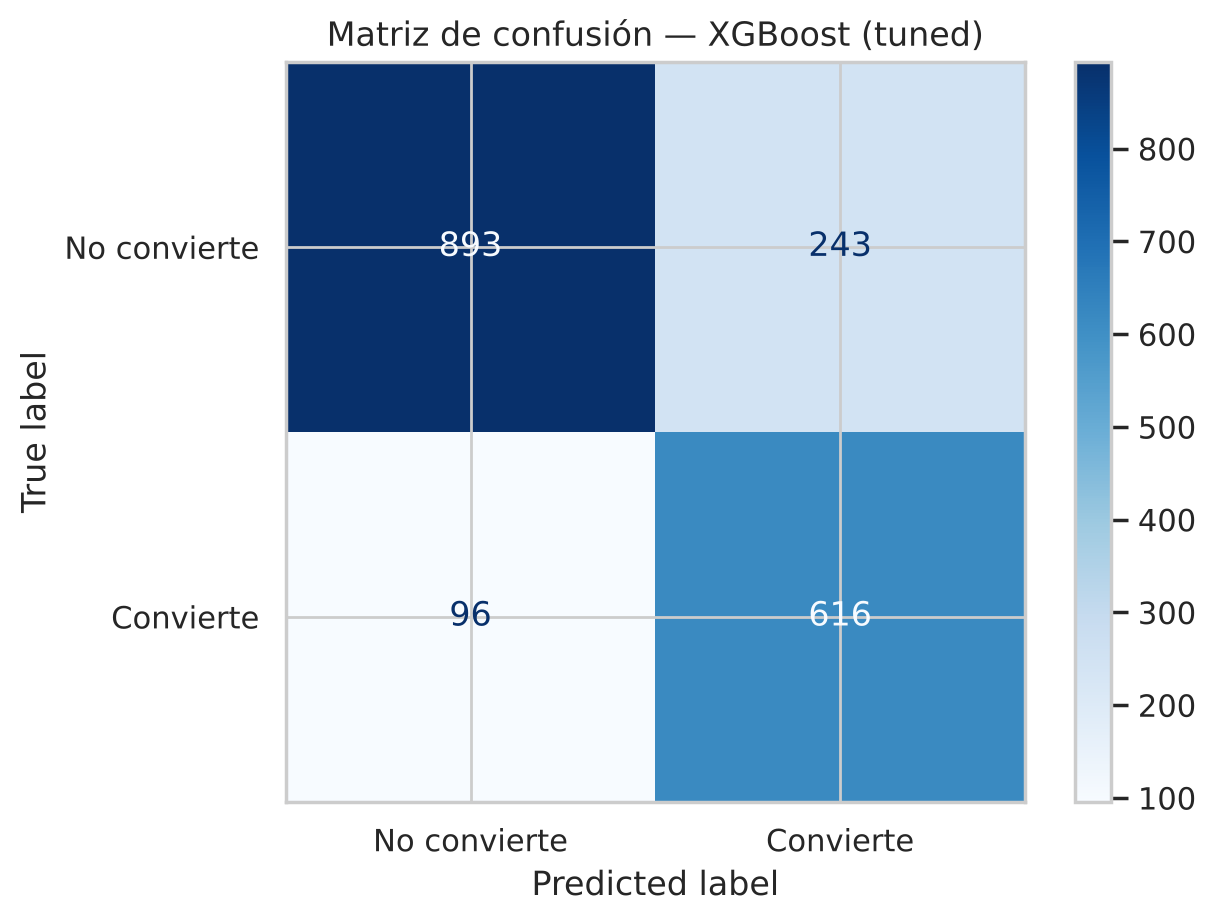

In [14]:
best_name = results_df.loc[0, "Modelo"]
best_model = models[best_name]
p_best = test_probas[best_name]

# Umbral óptimo (estadístico J de Youden)
fpr, tpr, thr = roc_curve(y_test, p_best)
best_thr = float(thr[np.argmax(tpr - fpr)])
y_pred = (p_best >= best_thr).astype(int)
print(f"Modelo seleccionado: {best_name}  |  umbral óptimo = {best_thr:.3f}\n")
print(classification_report(y_test, y_pred, target_names=["No convierte", "Convierte"]))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["No convierte", "Convierte"]).plot(cmap="Blues")
plt.title(f"Matriz de confusión — {best_name}"); plt.show()

## 7. Importancia de variables

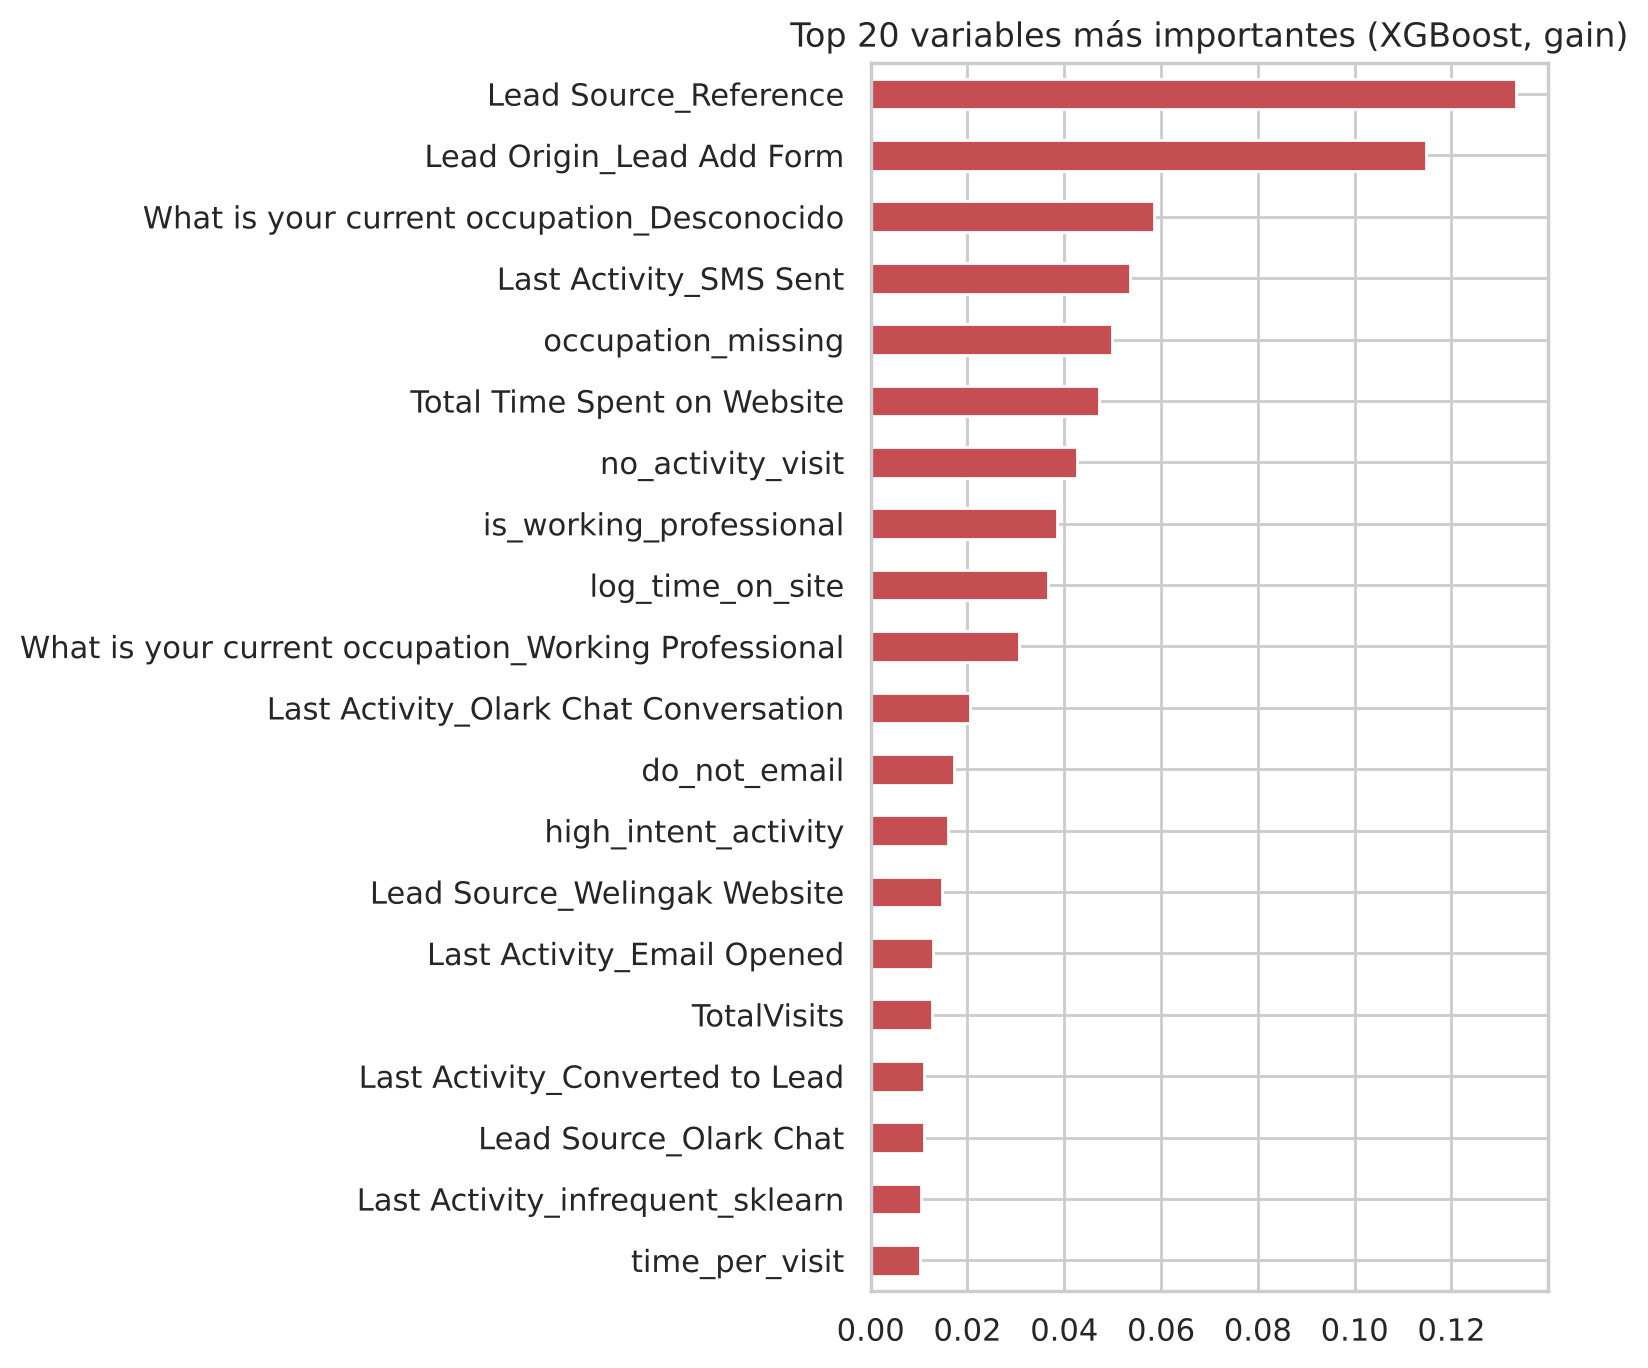

In [15]:
xgb_pipe = models["XGBoost (tuned)"]
feat_names = xgb_pipe.named_steps["preprocess"].get_feature_names_out()
feat_names = [n.split("__", 1)[1] for n in feat_names]
imp = pd.Series(xgb_pipe.named_steps["model"].feature_importances_, index=feat_names).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 7))
imp.head(20).sort_values().plot.barh(ax=ax, color="#C44E52")
ax.set_title("Top 20 variables más importantes (XGBoost, gain)"); plt.tight_layout(); plt.show()

## 8. Ranking de leads y sistema de priorización

El modelo produce una **probabilidad de conversión**, que se lleva a un **score de 0 a 100**.
Con ese score se ordenan los leads (ranking) y se asignan a un nivel con una acción comercial concreta:

| Nivel | Score | Acción sugerida |
|---|---|---|
| 🔥 Caliente | ≥ 70 | Llamar hoy: asignar a un asesor senior |
| 🌤 Tibio | 40 – 69 | Contactar esta semana: llamada + email personalizado |
| ❄️ Frío | < 40 | Nurturing automático: secuencia de emails / SMS |

In [16]:
test_scored = score_leads(best_model, X_test.assign(Converted=y_test.values))
tier_summary = (test_scored.groupby("prioridad")
                .agg(leads=("score", "size"), conversion_real=("Converted", "mean"), score_medio=("score", "mean"))
                .reindex(["Caliente", "Tibio", "Frío"]))
tier_summary["% de leads"] = tier_summary["leads"] / len(test_scored)
tier_summary["% de conversiones capturadas"] = test_scored.groupby("prioridad")["Converted"].sum() / test_scored["Converted"].sum()
tier_summary.style.format({"conversion_real": "{:.1%}", "score_medio": "{:.1f}", "% de leads": "{:.1%}",
                           "% de conversiones capturadas": "{:.1%}"})

,leads,conversion_real,score_medio,% de leads,% de conversiones capturadas
prioridad,,,,,
Caliente,491,83.1%,85.6,26.6%,57.3%
Tibio,288,59.7%,58.5,15.6%,24.2%
Frío,1069,12.3%,12.6,57.8%,18.5%


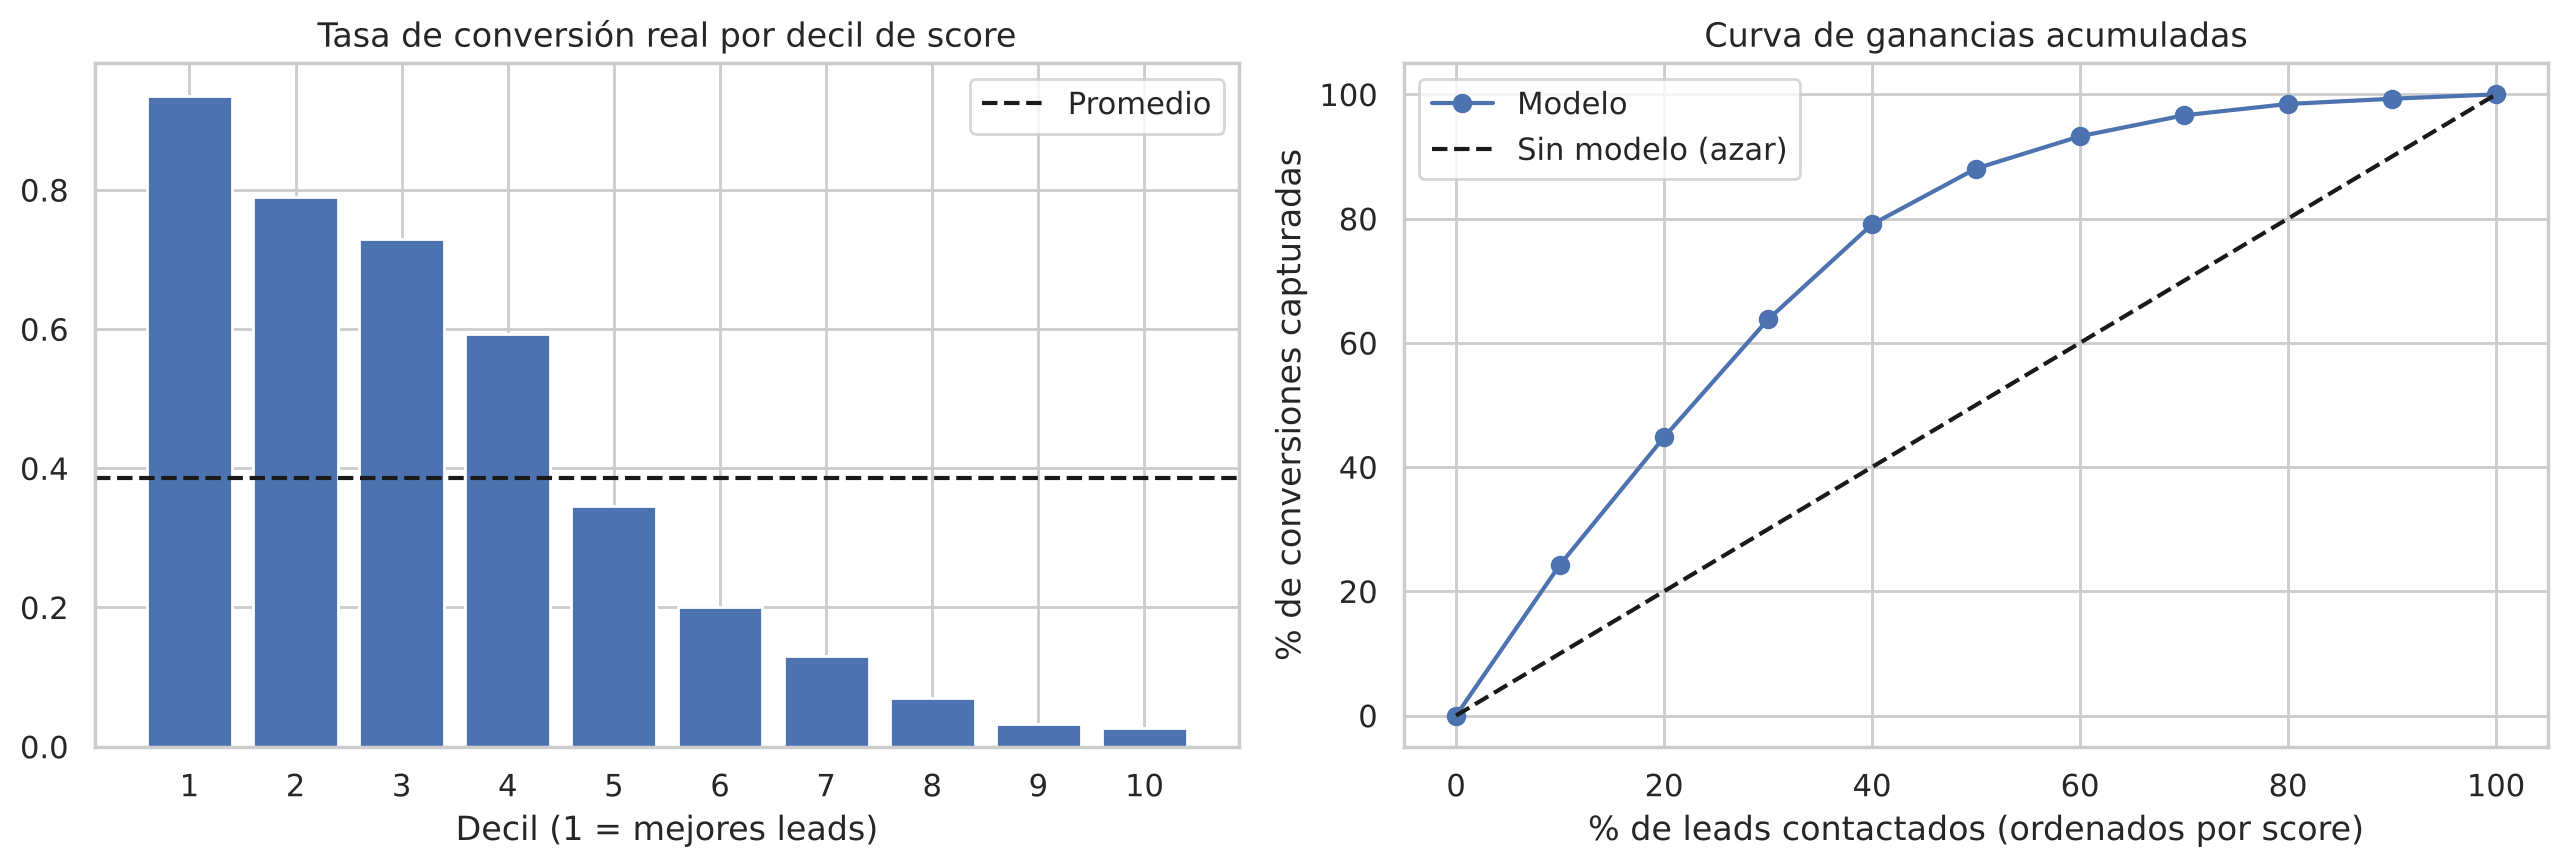

Contactando solo el 30% superior del ranking se captura el 64% de las conversiones.


,leads,conversiones,tasa_conversion,% acumulado capturado,lift
decil,,,,,
1,185,173,93.5%,24.3%,2.43
2,185,146,78.9%,44.8%,2.05
3,185,135,73.0%,63.8%,1.89
4,184,109,59.2%,79.1%,1.54
5,185,64,34.6%,88.1%,0.90
6,185,37,20.0%,93.3%,0.52
7,184,24,13.0%,96.6%,0.34
8,185,13,7.0%,98.5%,0.18
9,185,6,3.2%,99.3%,0.08


In [17]:
# Tabla de ganancias (gains/lift) por decil: ¿cuántas conversiones capturo contactando al top X%?
test_scored["decil"] = pd.qcut(test_scored["ranking"], 10, labels=range(1, 11))
gains = test_scored.groupby("decil", observed=True).agg(leads=("Converted", "size"), conversiones=("Converted", "sum"))
gains["tasa_conversion"] = gains["conversiones"] / gains["leads"]
gains["% acumulado capturado"] = gains["conversiones"].cumsum() / gains["conversiones"].sum()
gains["lift"] = gains["tasa_conversion"] / test_scored["Converted"].mean()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(gains.index.astype(str), gains["tasa_conversion"], color="#4C72B0")
ax[0].axhline(test_scored["Converted"].mean(), ls="--", c="k", label="Promedio")
ax[0].set_title("Tasa de conversión real por decil de score"); ax[0].set_xlabel("Decil (1 = mejores leads)"); ax[0].legend()
x = np.r_[0, np.arange(1, 11) * 10]
ax[1].plot(x, np.r_[0, gains["% acumulado capturado"].values * 100], marker="o", label="Modelo")
ax[1].plot([0, 100], [0, 100], "k--", label="Sin modelo (azar)")
ax[1].set_title("Curva de ganancias acumuladas"); ax[1].set_xlabel("% de leads contactados (ordenados por score)")
ax[1].set_ylabel("% de conversiones capturadas"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Contactando solo el 30% superior del ranking se captura el {gains['% acumulado capturado'].iloc[2]:.0%} de las conversiones.")
gains.style.format({"tasa_conversion": "{:.1%}", "% acumulado capturado": "{:.1%}", "lift": "{:.2f}"})

## 9. Modelo final y exportación

1. Se generan **scores fuera de muestra** (out-of-fold, 5 folds) para todos los leads; son los que muestra el dashboard,
   así la conversión por nivel no queda inflada.
2. El modelo final se **reentrena con todos los datos** y se guarda en `models/lead_scoring_model.joblib`.

In [18]:
import joblib
from sklearn.base import clone

final_model = clone(best_model)
oof = cross_val_predict(final_model, X, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
print(f"ROC-AUC fuera de muestra (todo el dataset): {roc_auc_score(y, oof):.4f}")

final_model.fit(X, y)
joblib.dump(final_model, "models/lead_scoring_model.joblib")

class _OOF:  # envoltorio para reutilizar score_leads con las probabilidades OOF
    def predict_proba(self, _):
        return np.c_[1 - oof, oof]
scored_all = score_leads(_OOF(), df[["Prospect ID", "Lead Number"] + INPUT_COLS + [TARGET]])
scored_all.to_csv("data/leads_scored.csv", index=False)

metadata = {
    "model_name": best_name,
    "trained_at": pd.Timestamp.now().isoformat(timespec="seconds"),
    "n_train_rows": int(len(X)),
    "conversion_rate": float(y.mean()),
    "optimal_threshold": best_thr,
    "metrics": results_df.round(4).to_dict(orient="records"),
    "oof_roc_auc": float(roc_auc_score(y, oof)),
    "tiers": [{"min_score": t, "tier": n, "action": a} for t, n, a in TIERS],
    "feature_importance": imp.head(20).round(4).to_dict(),
    "input_fields": INPUT_COLS,
    "versions": {"scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "pandas": pd.__version__},
}
with open("models/metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)
print("Guardado: models/lead_scoring_model.joblib, models/metadata.json, data/leads_scored.csv")
scored_all[["ranking", "Lead Number", "score", "prioridad", "accion_sugerida", "Lead Source", "Converted"]].head(10)

ROC-AUC fuera de muestra (todo el dataset): 0.9050


Guardado: models/lead_scoring_model.joblib, models/metadata.json, data/leads_scored.csv


,ranking,Lead Number,score,prioridad,accion_sugerida,Lead Source,Converted
4955,1,612484,98.8,Caliente,Llamar hoy: asignar a un asesor senior,Google,1
9100,2,580595,98.7,Caliente,Llamar hoy: asignar a un asesor senior,Google,1
3285,3,628517,98.7,Caliente,Llamar hoy: asignar a un asesor senior,Google,1
7719,4,590623,98.7,Caliente,Llamar hoy: asignar a un asesor senior,Organic Search,1
2055,5,639824,98.7,Caliente,Llamar hoy: asignar a un asesor senior,Direct Traffic,1
7227,6,593999,98.7,Caliente,Llamar hoy: asignar a un asesor senior,Organic Search,1
8568,7,584341,98.7,Caliente,Llamar hoy: asignar a un asesor senior,Organic Search,1
7094,8,595141,98.6,Caliente,Llamar hoy: asignar a un asesor senior,Organic Search,1
7171,9,594486,98.6,Caliente,Llamar hoy: asignar a un asesor senior,Organic Search,1
4935,10,612679,98.6,Caliente,Llamar hoy: asignar a un asesor senior,Google,1


## 10. Consumo del endpoint

La API (`api/main.py`, FastAPI) expone el modelo. Una vez desplegada (ver README), pon su URL abajo.
Si `API_URL` está vacío, se prueba el modelo localmente con el mismo formato de entrada.

In [19]:
API_URL = ""  # ej.: "https://lead-scoring-api.onrender.com"

nuevo_lead = {
    "lead_origin": "Landing Page Submission", "lead_source": "Google", "do_not_email": "No",
    "total_visits": 5, "total_time_spent_on_website": 1200, "page_views_per_visit": 3,
    "last_activity": "SMS Sent", "country": "India", "specialization": "Finance Management",
    "current_occupation": "Working Professional", "city": "Mumbai", "free_copy_mastering_interview": "No",
}

if API_URL:
    import requests
    r = requests.post(f"{API_URL}/predict", json=nuevo_lead, timeout=60)
    print(r.status_code, r.json())
else:
    field_map = dict(zip(["lead_origin", "lead_source", "do_not_email", "total_visits", "total_time_spent_on_website",
                          "page_views_per_visit", "last_activity", "country", "specialization", "current_occupation",
                          "city", "free_copy_mastering_interview"], INPUT_COLS))
    row = pd.DataFrame([{field_map[k]: v for k, v in nuevo_lead.items()}])
    print(score_leads(final_model, row)[["probabilidad", "score", "prioridad", "accion_sugerida"]].to_dict("records")[0])

{'probabilidad': 0.9848, 'score': 98.5, 'prioridad': 'Caliente', 'accion_sugerida': 'Llamar hoy: asignar a un asesor senior'}


## 11. Conclusiones

- Se excluyeron variables con **fuga de información** (`Tags`, `Lead Quality`, etc.). Así el modelo es honesto
  y sirve para puntuar leads nuevos, a costa de un AUC menor que el de muchos notebooks públicos que las usan.
- Los modelos de **boosting (XGBoost / Gradient Boosting)** obtienen el mejor ROC-AUC (~0.89 en test).
  La red neuronal y la regresión logística quedan cerca, lo que indica que la señal está dominada por pocas variables fuertes.
- Las variables más influyentes son la **fuente** (`Reference`), el **origen del lead** (`Lead Add Form`), la **ocupación**
  (y si se dejó en blanco), la **última actividad** (SMS enviado) y el **tiempo en el sitio**.
- El sistema de priorización concentra las conversiones: contactar solo el **30% superior** del ranking captura
  cerca de **2 de cada 3 conversiones**, lo que permite enfocar al equipo comercial.

**Trabajo futuro:** calibración de probabilidades, monitoreo de drift y reentrenamiento periódico con datos del CRM.